# Fricative stimuli analysis

This notebook analyzes the stimuli used in the experiment and produces a figure for the paper.
The notebook `notebooks/multiarrange_analysis.py` uses the outputs while analyzing the perceptual data.

## A word on normalization

The stimuli analyzed in this script have already been normalized.
All of the `wav` files for the stimuli were concatenated together and the max amplitude of the concatenation was scaled to one.
More details are relayed in the paper.

## Preliminaries

The first two cells are preliminaries: imports and default labels for the fricatives.
Change `SAVE_FIGURE_MODE` to `True` if the figure outputs are to be saved.

In [1]:
# Imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import phonlab
import re
from pathlib import Path
from collections import namedtuple
from scipy.fft import dct
from fileorganize import dir_to_df
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=['#002676', '#FDB515', '#00553A', '#770747', '#431170'])
import pypst

In [2]:
# Constants, including directories.
DEFAULT_FRICATIVE_LABELS: tuple[str, ...] = ("bilabial", 
                                        "labio-dental", 
                                        "dental", 
                                        "alveolar", 
                                        "palato-alveolar", 
                                        "retroflex", 
                                        "alveolo-palatal", 
                                        "palatal", 
                                        "velar", 
                                        "uvular", 
                                        "pharyngeal", 
                                        "glottal",)

labels_key = {label: number for number, label in enumerate(DEFAULT_FRICATIVE_LABELS)}

project_dir = Path.cwd().parent
STIMULI_DIR = 'stimuli/normalized/wikicommons_initial'
FIGURE_DIR = project_dir / 'figures/'
RESULTS_DIR = 'data/results/'
TEXTGRID_DIR = Path('../stimuli/normalized/wikicommons_whole_files/')


SAVE_FIGURE_MODE = False
SAVE_OUTPUT_MODE = False

## Spectral characteristics

For this analysis, we use the `stimuli/normalized/wikicommons_initial` directory.
Each file contains 200ms of the normalized fricative, extracted from the center of the fricative.
The labio-dental fricative was only 183ms long, so the entire fricative is used. 

The script extracts spectral measurements using the `phonlab.fricative()` function at ten equidistant points in the audio sample. 
It uses `scipy.fft.dct()` to calculate the first four discrete cosine transform coefficients as well.

In [3]:
measurement_percentiles = np.linspace(0.1, 0.9, 9)

files_df = []
measurements_df = []
for file in (project_dir / STIMULI_DIR).iterdir():
    sig, sr = phonlab.loadsig(file)
    assert sig.ndim == 1
    filename = file.name
    fricative_label = re.search(r"^(.+)_", filename).group(1)
    duration = sig.shape[0]/sr
    files_df.append({
        'signal': sig,
        'sampling_rate': sr,
        'filename': filename,
        'fricative_label': fricative_label
    })
    for percentile in measurement_percentiles:
        t = duration * percentile
        measurements = phonlab.fricative(sig, sr, t)
        dcts = dct(measurements.spec)[0:4]
        measurements_df.append({
            'filename': filename,
            'fricative_label': fricative_label,
            'time': t,            
            'percentile': percentile,
            **measurements._asdict(),
            'DCT0': dcts[0],
            'DCT1': dcts[1],
            'DCT2': dcts[2],
            'DCT3': dcts[3],
        })
files_df = pd.DataFrame(files_df)
measurements_df = pd.DataFrame(measurements_df)
for fric in measurements_df['fricative_label']:
    assert fric in DEFAULT_FRICATIVE_LABELS
measurements_df = (measurements_df
    .sort_values(['fricative_label', 'percentile'], 
                 key=lambda x: x if x.dtype == 'float64' else x.apply(labels_key.get))
    .reset_index(drop=True)
                  )
measurements_df.head()

,filename,fricative_label,time,percentile,Fm,Am,AmpD,Fsec,Asec,mode,COG,SD,Skew,Kurtosis,spec,freq,DCT0,DCT1,DCT2,DCT3
0,bilabial_initial.wav,bilabial,0.02005,0.1,1600.0,-38.494567,9.731698,3600.0,-37.459975,500/50%/8dB,4100.519758,2622.897154,0.582247,-0.515022,"[-33.16995334903767, -30.172168444913066, -31....","[0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0,...",-37916.545034,5993.263573,-346.876808,898.326268
1,bilabial_initial.wav,bilabial,0.04010,0.2,2550.0,-39.593105,8.498785,NaN,NaN,500/50%/8dB,4154.823932,2538.509038,0.523847,-0.451571,"[-28.020981835426714, -24.74734986124078, -24....","[0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0,...",-36227.841576,5380.913949,-530.275723,443.378313
2,bilabial_initial.wav,bilabial,0.06015,0.3,2550.0,-34.506097,13.556520,3650.0,-33.742622,500/50%/8dB,4233.579322,2629.813231,0.515660,-0.525637,"[-22.51079364825533, -19.61833294185196, -19.8...","[0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0,...",-35483.873338,6077.296457,-839.937951,925.956872
3,bilabial_initial.wav,bilabial,0.08020,0.4,2600.0,-35.665968,11.239639,6800.0,-41.780595,500/50%/8dB,4391.067305,2633.981757,0.387602,-0.719991,"[-30.65278658289205, -27.459808430946048, -28....","[0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0,...",-34873.247566,5946.408676,-869.979480,317.921638
4,bilabial_initial.wav,bilabial,0.10025,0.5,3650.0,-31.592192,13.365099,6800.0,-42.771847,500/50%/8dB,3969.682393,2405.123759,0.490947,-0.434943,"[-24.921437081393428, -21.586987475206882, -21...","[0.0, 50.0, 100.0, 150.0, 200.0, 250.0, 300.0,...",-34142.603752,5506.469936,-393.702610,362.948242


Now we'll plot sample spectra for each stimulus.
For each stimulus, we'll take the sample with the Fm measurement closest to the median and use that for plotting.

In [4]:
# Helper function to find the spectral measurements at the point closest to the median Fm value
def closest_to_median(group):
    med = group['Fm'].median()
    idx = (group['Fm'] - med).abs().idxmin()
    return group.loc[idx]

# Create a dataframe of just those spectral measurements
plotframe = (measurements_df.groupby('fricative_label')
    .apply(closest_to_median, include_groups=False)
    .reset_index()
    .sort_values(['fricative_label', 'percentile'], key=lambda x: x if x.dtype == 'float64' else x.apply(labels_key.get))
    .reset_index(drop=True)
            )

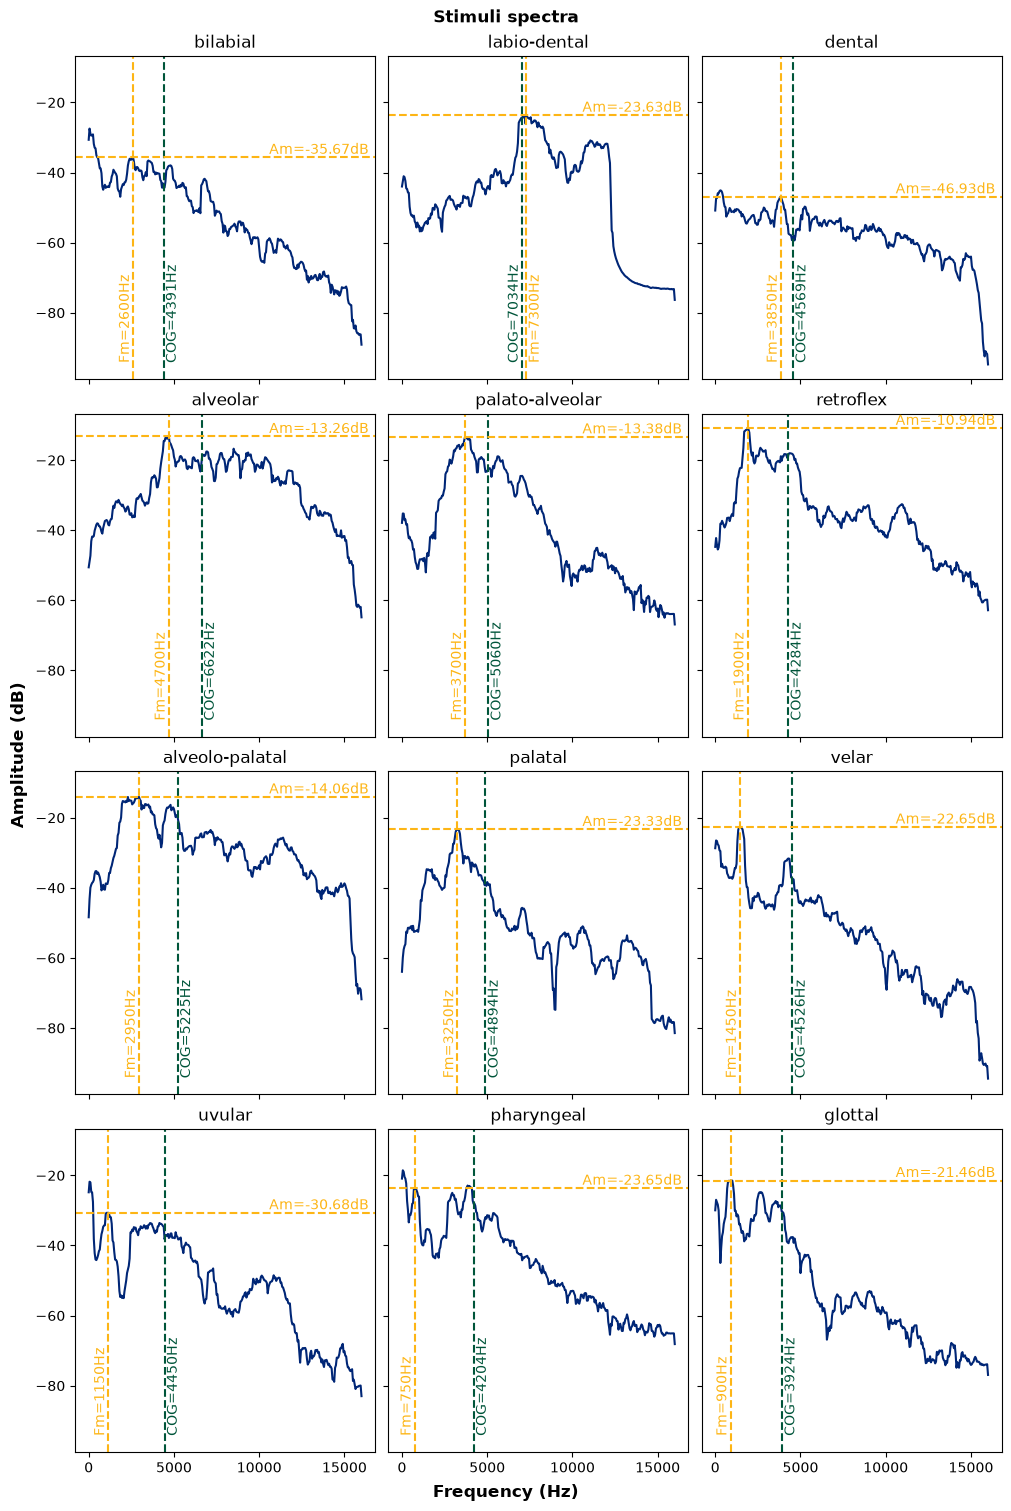

In [5]:
nrow = 4
ncol = 3
fig, axes = plt.subplots(nrow, ncol, sharex = True, sharey=True, figsize=(10, 15), constrained_layout=True,)

for row in plotframe.itertuples():
    ax = axes[row.Index // 3, row.Index % 3]
    ax.plot(row.freq, row.spec)
    ax.axvline(row.COG, color = '#00553A', linestyle='--')
    ax.axvline(row.Fm, color='#FDB515', linestyle='--')
    ax.axhline(row.Am, color='#FDB515', linestyle='--')
    if row.Fm < row.COG:
        ax.text(row.Fm - 50, 0.05, f"Fm={row.Fm:.0f}Hz", rotation=90, color = '#FDB515', ha='right', va='bottom', transform=ax.get_xaxis_transform())
        ax.text(row.COG + 100, 0.05, f"COG={row.COG:.0f}Hz", rotation=90, color = '#00553A', ha='left', va='bottom', transform=ax.get_xaxis_transform())
    else:
        ax.text(row.Fm + 100, 0.05, f"Fm={row.Fm:.0f}Hz", rotation=90, color = '#FDB515', ha='left', va='bottom', transform=ax.get_xaxis_transform())
        ax.text(row.COG - 50, 0.05, f"COG={row.COG:.0f}Hz", rotation=90, color = '#00553A', ha='right', va='bottom', transform=ax.get_xaxis_transform())
    ax.text(.98, row.Am+1, f"Am={row.Am:.2f}dB", color="#FDB515", ha="right", transform=ax.get_yaxis_transform())
    ax.set_title(row.fricative_label)
    ax.annotate(f"{row.Fm:.0f}", xy=(row.Fm, -100))
    
fig.suptitle("Stimuli spectra", fontweight="bold")
fig.supylabel("Amplitude (dB)", fontweight="bold")
fig.supxlabel("Frequency (Hz)", fontweight="bold")
if SAVE_FIGURE_MODE:
    fig.savefig(FIGURE_DIR / 'stimuli_spectra.png')
plt.show()

## Duration data

Now we get data about the whole stimulus---basically, the duration of the segment and syllables.
Each TextGrid labels the /Fa aFa/ stimulus with a word tier, for the syllables, and a segment tier for the segments.

In [6]:
textgrids = dir_to_df(TEXTGRID_DIR).loc[lambda df: df['fname'].str.endswith('TextGrid')]

duration_df = []


for textgrid in textgrids['fname']:
    # Separate 'word' and 'segment' tiers into dataframes.
    word_df, segment_df = phonlab.tg_to_df(TEXTGRID_DIR / textgrid)

    # Find first non-empty cell in the 'word' dataframe.
    # This is our stimulus syllable. Save the data.
    for idx, t1, t2, word in word_df.itertuples():
        if word != '':
            syllable_t1 = t1
            syllable_t2 = t2
            syllable = word
            break

    # Find first two non-empty cells in the 'segment' dataframe.
    # These are our fricative segment and its following vowel.
    # Save the data
    counter = 0
    for idx, t1, t2, segment in segment_df.itertuples():
        if segment != '' and counter == 0:
            fricative_t1= t1
            fricative_t2 = t2
            fricative = segment
            counter += 1
        elif segment != '' and counter == 1:
            vowel_t1 = t1
            vowel_t2 = t2
            vowel = segment
            counter += 1

    # Store the data in a dictionary and append it to a list.
    duration_df.append({
        'textgrid_name': textgrid,
        'syllable_t1': syllable_t1,
        'syllable_t2': syllable_t2,
        'syllable': syllable,
        'fricative_t1': fricative_t1,
        'fricative_t2': fricative_t2,
        'fricative': fricative,
        'vowel_t1': vowel_t1,
        'vowel_t2': vowel_t2,
        'vowel': vowel,
    })

# Convert list into a dataframe and calculate duration data.
duration_df = pd.DataFrame(duration_df).assign(
    fricative_label = lambda x: x['textgrid_name'].str.extract(r"_(.+)_"),
    syllable_dur = lambda x: x['syllable_t2'] - x['syllable_t1'],
    fricative_dur = lambda x: x['fricative_t2'] - x['fricative_t1'],
    vowel_dur = lambda x: x['vowel_t2'] - x['vowel_t1'],
                                      )

# Retain only the relevant columns
duration_df = duration_df[['textgrid_name', 'fricative_label', 'fricative', 'fricative_dur', 'syllable', 'syllable_dur', 'vowel', 'vowel_dur']]

# Check that every row of the dataframe is actually one of our fricatives
for fric in duration_df['fricative_label']:
    assert fric in DEFAULT_FRICATIVE_LABELS

duration_df

,textgrid_name,fricative_label,fricative,fricative_dur,syllable,syllable_dur,vowel,vowel_dur
0,Voiceless_alveolar_sibilant.TextGrid,alveolar,s,0.232540,sa,0.624812,a,0.392272
1,Voiceless_alveolo-palatal_sibilant.TextGrid,alveolo-palatal,ɕ,0.341410,ɕa,0.948968,a,0.607558
2,Voiceless_bilabial_fricative.TextGrid,bilabial,ɸ,0.264700,ɸa,0.839804,a,0.575104
3,Voiceless_dental_fricative.TextGrid,dental,θ,0.225447,θa,0.736964,a,0.511517
4,Voiceless_glottal_fricative.TextGrid,glottal,h,0.277826,ha,0.795346,a,0.517520
5,Voiceless_labio-dental_fricative.TextGrid,labio-dental,f,0.183300,fa,0.600034,a,0.416734
6,Voiceless_palatal_fricative.TextGrid,palatal,ç,0.316191,ça,0.746748,a,0.430557
7,Voiceless_palato-alveolar_sibilant.TextGrid,palato-alveolar,ʃ,0.301005,ʃa,0.727261,a,0.426256
8,Voiceless_pharyngeal_fricative.TextGrid,pharyngeal,ħ,0.445029,ħa,0.955409,a,0.510380
9,Voiceless_retroflex_sibilant.TextGrid,retroflex,ʂ,0.392453,ʂa,0.849338,a,0.456885


Now we take the medians for each fricative's measurements in `measurements_df` and merge them with the `duration_df`.
If `SAVE_OUTPUT_MODE = True`, the resulting full dataframe is pickled, as `data/processed/fricative_df.pkl` to be used by `notebooks/multiarrange_analysis.py`.

In [7]:
# Find the medians of numeric columns in `measurements_df`
medians_df = measurements_df[['fricative_label', 'Fm', 'Am', 'AmpD',
       'Fsec', 'Asec', 'COG', 'SD', 'Skew', 'Kurtosis', 
       'DCT0', 'DCT1', 'DCT2', 'DCT3']].groupby('fricative_label').agg('median').reset_index()

# Merge medians_df with full_df
full_df = pd.merge(medians_df, duration_df).sort_values('fricative_label', key=lambda x: x.apply(labels_key.get)).reset_index(drop=True)

if SAVE_OUTPUT_MODE:
    full_df.to_pickle('../data/processed/fricative_df.pkl')
    
full_df 

,fricative_label,Fm,Am,AmpD,Fsec,Asec,COG,SD,Skew,Kurtosis,...,DCT1,DCT2,DCT3,textgrid_name,fricative,fricative_dur,syllable,syllable_dur,vowel,vowel_dur
0,bilabial,2600.0,-34.506097,11.239639,3675.0,-36.172456,4064.207102,2508.411885,0.523847,-0.434943,...,5805.578985,-346.876808,443.378313,Voiceless_bilabial_fricative.TextGrid,ɸ,0.264700,ɸa,0.839804,a,0.575104
1,labio-dental,7300.0,-24.414990,33.594388,11550.0,-23.144684,6700.434383,2623.390323,-0.398543,-0.615210,...,2069.551955,-5170.383364,1372.517598,Voiceless_labio-dental_fricative.TextGrid,f,0.183300,fa,0.600034,a,0.416734
2,dental,3850.0,-46.623232,9.337750,8900.0,-50.500271,4659.489558,2878.861708,0.344110,-0.844947,...,3299.578066,-1297.575862,922.430139,Voiceless_dental_fricative.TextGrid,θ,0.225447,θa,0.736964,a,0.511517
3,alveolar,4700.0,-15.228744,25.560026,8500.0,-16.749496,6640.699352,2580.280759,-0.255453,-0.775530,...,1036.998979,-3769.790899,269.004363,Voiceless_alveolar_sibilant.TextGrid,s,0.232540,sa,0.624812,a,0.392272
4,palato-alveolar,3700.0,-15.646612,33.768156,8975.0,-35.847555,5060.191553,2315.458592,0.216387,-0.567091,...,5674.619726,-2805.878315,-2061.508562,Voiceless_palato-alveolar_sibilant.TextGrid,ʃ,0.301005,ʃa,0.727261,a,0.426256
5,retroflex,1900.0,-12.386705,29.699317,4500.0,-16.727849,4338.046304,2522.515003,0.877648,0.017712,...,4431.480453,-1183.454760,327.542886,Voiceless_retroflex_sibilant.TextGrid,ʂ,0.392453,ʂa,0.849338,a,0.456885
6,alveolo-palatal,2950.0,-11.199468,31.821357,11600.0,-25.108888,5225.338150,2607.608641,0.368670,-0.846884,...,3312.326128,-2310.348399,-382.632520,Voiceless_alveolo-palatal_sibilant.TextGrid,ɕ,0.341410,ɕa,0.948968,a,0.607558
7,palatal,3250.0,-23.470208,24.052708,10200.0,-50.648924,4826.674262,2856.472363,0.460840,-0.796340,...,5207.549650,-572.032737,-339.241883,Voiceless_palatal_fricative.TextGrid,ç,0.316191,ça,0.746748,a,0.430557
8,velar,1450.0,-25.085878,16.644945,4300.0,-31.788717,4332.612274,2659.110492,0.439628,-0.735639,...,5651.643298,-465.722571,167.540821,Voiceless_velar_fricative.TextGrid,x,0.271175,xa,0.815274,a,0.544099
9,uvular,1150.0,-29.548622,14.731224,2800.0,-28.682022,4475.729736,2767.267394,0.645863,-0.302761,...,5660.371267,-1049.925099,663.989345,Voiceless_uvular_fricative.TextGrid,χ,0.278378,χa,0.833394,a,0.555016
